In [2]:
%%writefile matMul.cu
#include <cuda_fp16.h>
#include <cuda_runtime.h>
#include <mma.h>
#include <omp.h>

#include <algorithm>
#include <cerrno>
#include <chrono>
#include <climits>
#include <cmath>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <vector>

using namespace nvcuda;

#ifdef USE_FLOAT
using DataType = float;
constexpr const char *TYPE_NAME = "float";
constexpr double EPSILON = 1e-3;
#else
using DataType = double;
constexpr const char *TYPE_NAME = "double";
constexpr double EPSILON = 1e-6;
#endif

constexpr int BLOCK_SIZE = 16;
constexpr int TILE_K = 16;
constexpr int GPU_RUNS = 10;

// WMMA fragment dimensions supported on Turing (sm_75) Tensor Cores for FP16 -> FP32
constexpr int WMMA_M = 16;
constexpr int WMMA_N = 16;
constexpr int WMMA_K = 16;
constexpr int WARP_SIZE = 32;

#define CUDA_CHECK(call)                                                     \
    do {                                                                     \
        cudaError_t err = (call);                                            \
        if (err != cudaSuccess) {                                            \
            fprintf(stderr, "%s:%d: %s\n", __FILE__, __LINE__,               \
                    cudaGetErrorString(err));                                \
            exit(EXIT_FAILURE);                                              \
        }                                                                    \
    } while (0)

// Baseline naive GEMM kernel (from Assignment 2)
__global__ void gemm(const DataType *A, const DataType *B, DataType *C,
                     int M, int K, int N) {
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    if (row < M && col < N) {
        DataType sum = 0;
        for (int k = 0; k < K; ++k) {
            sum += A[static_cast<size_t>(row) * K + k] *
                   B[static_cast<size_t>(k) * N + col];
        }
        C[static_cast<size_t>(row) * N + col] = sum;
    }
}

// Shared-memory tiled GEMM kernel (from Assignment 2)
__global__ void tiled_gemm(const DataType *A, const DataType *B, DataType *C,
                           int M, int K, int N, int tileX, int tileY) {
    extern __shared__ DataType shared[];
    DataType *tileA = shared;
    DataType *tileB = shared + tileY * TILE_K;

    int firstRow = blockIdx.y * tileY;
    int firstCol = blockIdx.x * tileX;
    int row = firstRow + threadIdx.y;
    int col = firstCol + threadIdx.x;
    int thread = threadIdx.y * tileX + threadIdx.x;
    int threads = tileX * tileY;

    DataType sum = 0;
    for (int firstK = 0; firstK < K; firstK += TILE_K) {
        for (int i = thread; i < tileY * TILE_K; i += threads) {
            int inputRow = firstRow + i / TILE_K;
            int k = firstK + i % TILE_K;
            tileA[i] = inputRow < M && k < K
                           ? A[static_cast<size_t>(inputRow) * K + k]
                           : DataType{0};
        }
        for (int i = thread; i < TILE_K * tileX; i += threads) {
            int k = firstK + i / tileX;
            int inputCol = firstCol + i % tileX;
            tileB[i] = k < K && inputCol < N
                           ? B[static_cast<size_t>(k) * N + inputCol]
                           : DataType{0};
        }
        __syncthreads();

        for (int k = 0; k < TILE_K; ++k) {
            sum += tileA[threadIdx.y * TILE_K + k] *
                   tileB[k * tileX + threadIdx.x];
        }
        __syncthreads();
    }

    if (row < M && col < N) {
        C[static_cast<size_t>(row) * N + col] = sum;
    }
}

// Precision conversion kernel: converts input matrices from DataType (double) to FP16 (half)
__global__ void convert_to_half(const DataType *src, half *dst, size_t count) {
    // Compute global 1D thread index
    size_t idx = static_cast<size_t>(blockIdx.x) * blockDim.x + threadIdx.x;
    // Convert each valid element to IEEE 754 half precision via float
    if (idx < count) {
        dst[idx] = __float2half(static_cast<float>(src[idx]));
    }
}

// Tensor Core mixed-precision WMMA GEMM kernel (FP16 multiply, FP32 accumulate)
// Each warp computes one 16x16 output tile of C
__global__ void wmma_gemm(const half *A, const half *B, float *C,
                          int M, int K, int N) {
    // Identify this warp's unique global index across the 1D grid
    int globalWarpId = (blockIdx.x * blockDim.x + threadIdx.x) / WARP_SIZE;

    // Number of 16x16 tiles along rows (M) and columns (N)
    int tilesM = M / WMMA_M;
    int tilesN = N / WMMA_N;

    // Map global warp ID to its 2D output tile coordinates
    int tileRow = globalWarpId / tilesN;
    int tileCol = globalWarpId % tilesN;

    // Guard against extra warps in the last block
    if (tileRow >= tilesM || tileCol >= tilesN) {
        return;
    }

    // Starting row and column indices of this warp's 16x16 tile in matrix C
    int cRow = tileRow * WMMA_M;
    int cCol = tileCol * WMMA_N;

    // Declare WMMA fragments: FP16 inputs (row-major) and FP32 accumulator
    wmma::fragment<wmma::matrix_a, WMMA_M, WMMA_N, WMMA_K, half, wmma::row_major> aFrag;
    wmma::fragment<wmma::matrix_b, WMMA_M, WMMA_N, WMMA_K, half, wmma::row_major> bFrag;
    wmma::fragment<wmma::accumulator, WMMA_M, WMMA_N, WMMA_K, float> cFrag;

    // Initialize accumulator fragment to zero
    wmma::fill_fragment(cFrag, 0.0f);

    // Accumulate partial products across the K dimension in steps of WMMA_K (16)
    for (int k = 0; k < K; k += WMMA_K) {
        // Compute pointers to the current 16x16 tiles in A and B
        const half *tileA = A + static_cast<size_t>(cRow) * K + k;
        const half *tileB = B + static_cast<size_t>(k) * N + cCol;

        // Step 1: Load 16x16 matrix tiles into Tensor Core fragments (leading dims: K for A, N for B)
        wmma::load_matrix_sync(aFrag, tileA, K);
        wmma::load_matrix_sync(bFrag, tileB, N);

        // Step 2: Execute hardware Matrix Multiply-Accumulate on Tensor Cores
        wmma::mma_sync(cFrag, aFrag, bFrag, cFrag);
    }

    // Step 3: Store the 16x16 FP32 accumulator fragment back to global memory (row-major)
    float *tileC = C + static_cast<size_t>(cRow) * N + cCol;
    wmma::store_matrix_sync(tileC, cFrag, N, wmma::mem_row_major);
}

// Row-major traversal of B and C with OpenMP multi-threading across rows
void cpu_gemm(const DataType *A, const DataType *B, DataType *C,
              int M, int K, int N) {
    #pragma omp parallel for schedule(static)
    for (int row = 0; row < M; ++row) {
        DataType *output = C + static_cast<size_t>(row) * N;
        std::fill_n(output, N, DataType{0});
        for (int k = 0; k < K; ++k) {
            DataType a = A[static_cast<size_t>(row) * K + k];
            const DataType *input = B + static_cast<size_t>(k) * N;
            for (int col = 0; col < N; ++col) {
                output[col] += a * input[col];
            }
        }
    }
}

bool validate(const std::vector<DataType> &output,
              const std::vector<DataType> &reference, double &maxError) {
    size_t mismatches = 0;
    maxError = 0;
    for (size_t i = 0; i < output.size(); ++i) {
        double expected = reference[i];
        double error = std::fabs(static_cast<double>(output[i]) - expected);
        maxError = std::isfinite(error) ? std::max(maxError, error) : HUGE_VAL;
        if (!(error <= EPSILON * (1.0 + std::fabs(expected)))) {
            ++mismatches;
        }
    }
    if (mismatches != 0) {
        fprintf(stderr, "%zu GPU output elements failed validation\n", mismatches);
    }
    return mismatches == 0;
}

// Computes accuracy loss statistics for mixed-precision WMMA output against CPU reference
struct AccuracyStats {
    double maxAbsError;
    double meanAbsError;
    double rmse;
    double meanRelErrorPct;
    double maxRelErrorPct;
};

AccuracyStats evaluate_wmma_accuracy(const std::vector<float> &output,
                                     const std::vector<DataType> &reference) {
    AccuracyStats stats{0.0, 0.0, 0.0, 0.0, 0.0};
    double sumAbs = 0.0;
    double sumSq = 0.0;
    double sumRel = 0.0;
    const size_t n = output.size();

    for (size_t i = 0; i < n; ++i) {
        double ref = static_cast<double>(reference[i]);
        double val = static_cast<double>(output[i]);
        double absErr = std::fabs(val - ref);
        double relErr = absErr / (std::fabs(ref) + 1e-12);

        stats.maxAbsError = std::max(stats.maxAbsError, absErr);
        stats.maxRelErrorPct = std::max(stats.maxRelErrorPct, relErr * 100.0);
        sumAbs += absErr;
        sumSq += absErr * absErr;
        sumRel += relErr;
    }

    stats.meanAbsError = sumAbs / static_cast<double>(n);
    stats.rmse = std::sqrt(sumSq / static_cast<double>(n));
    stats.meanRelErrorPct = (sumRel / static_cast<double>(n)) * 100.0;
    return stats;
}

struct Tile {
    int x;
    int y;
};

bool parse_dimension(const char *arg, int &value) {
    char *end;
    errno = 0;
    long parsed = strtol(arg, &end, 10);
    if (errno != 0 || end == arg || *end != '\0' || parsed < 1 ||
        parsed > INT_MAX - 32) {
        return false;
    }
    value = static_cast<int>(parsed);
    return true;
}

int main(int argc, char **argv) {
    int M, K, N;
    bool csv = false;
    bool profile = false;
    bool wmmaOnly = false;
    int wmmaThreadsPerBlock = 256;

    if (argc < 4 || !parse_dimension(argv[1], M) ||
        !parse_dimension(argv[2], K) || !parse_dimension(argv[3], N)) {
        fprintf(stderr, "Usage: %s M K N [--csv] [--profile] [--wmma-only] [--tpb N]\n", argv[0]);
        return EXIT_FAILURE;
    }

    // Parse optional flags after M K N
    for (int i = 4; i < argc; ++i) {
        if (strcmp(argv[i], "--csv") == 0) {
            csv = true;
        } else if (strcmp(argv[i], "--profile") == 0) {
            profile = true;
        } else if (strcmp(argv[i], "--wmma-only") == 0) {
            wmmaOnly = true;
        } else if (strcmp(argv[i], "--tpb") == 0 && i + 1 < argc) {
            if (!parse_dimension(argv[++i], wmmaThreadsPerBlock) ||
                wmmaThreadsPerBlock < 32 || wmmaThreadsPerBlock > 1024 ||
                wmmaThreadsPerBlock % WARP_SIZE != 0) {
                fprintf(stderr, "Error: --tpb must be a multiple of 32 in [32, 1024]\n");
                return EXIT_FAILURE;
            }
        } else {
            fprintf(stderr, "Unknown option: %s\n", argv[i]);
            return EXIT_FAILURE;
        }
    }

    if (M % WMMA_M != 0 || K % WMMA_K != 0 || N % WMMA_N != 0) {
        fprintf(stderr, "Error: M, K, and N must be multiples of 16 for WMMA\n");
        return EXIT_FAILURE;
    }

    int device;
    cudaDeviceProp properties;
    CUDA_CHECK(cudaGetDevice(&device));
    CUDA_CHECK(cudaGetDeviceProperties(&properties, device));
    if ((M + 7) / 8 > properties.maxGridSize[1] ||
        (N + 7) / 8 > properties.maxGridSize[0]) {
        fprintf(stderr, "Matrix dimensions exceed the supported CUDA grid size\n");
        return EXIT_FAILURE;
    }

    std::vector<DataType> A(static_cast<size_t>(M) * K);
    std::vector<DataType> B(static_cast<size_t>(K) * N);
    std::vector<DataType> reference(static_cast<size_t>(M) * N);
    std::vector<DataType> output(reference.size());
    std::vector<float> wmmaOutput(reference.size());

    srand(42);
    for (DataType &a : A) a = static_cast<DataType>((rand() % 100) / 100.0);
    for (DataType &b : B) b = static_cast<DataType>((rand() % 100) / 100.0);

    double cpuMs = 0.0;
    if (!wmmaOnly) {
        auto start = std::chrono::steady_clock::now();
        cpu_gemm(A.data(), B.data(), reference.data(), M, K, N);
        cpuMs = std::chrono::duration<double, std::milli>(
                    std::chrono::steady_clock::now() - start)
                    .count();
    }

    // Allocate device memory for FP64 baseline and FP16/FP32 WMMA buffers
    DataType *dA, *dB, *dC;
    half *dA_half, *dB_half;
    float *dC_float;
    size_t bytesA = A.size() * sizeof(DataType);
    size_t bytesB = B.size() * sizeof(DataType);
    size_t bytesC = output.size() * sizeof(DataType);

    CUDA_CHECK(cudaMalloc(&dA, bytesA));
    CUDA_CHECK(cudaMalloc(&dB, bytesB));
    CUDA_CHECK(cudaMalloc(&dC, bytesC));
    CUDA_CHECK(cudaMalloc(&dA_half, A.size() * sizeof(half)));
    CUDA_CHECK(cudaMalloc(&dB_half, B.size() * sizeof(half)));
    CUDA_CHECK(cudaMalloc(&dC_float, wmmaOutput.size() * sizeof(float)));

    CUDA_CHECK(cudaMemcpy(dA, A.data(), bytesA, cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(dB, B.data(), bytesB, cudaMemcpyHostToDevice));

    cudaEvent_t begin, end;
    CUDA_CHECK(cudaEventCreate(&begin));
    CUDA_CHECK(cudaEventCreate(&end));

    // Calculate fragment statistics for Question 1
    long long tilesM = M / WMMA_M;
    long long tilesN = N / WMMA_N;
    long long tilesK = K / WMMA_K;
    long long cFragments = tilesM * tilesN;
    long long distinctTiles = tilesM * tilesK + tilesK * tilesN + cFragments;
    long long totalFragOps = 2LL * cFragments * tilesK + cFragments;

    const Tile configurations[] = {{BLOCK_SIZE, BLOCK_SIZE}, {8, 8}, {16, 16}, {32, 8}};
    float gpuMs[4] = {0.0f, 0.0f, 0.0f, 0.0f};
    bool allValid = true;
    int runs = (profile || wmmaOnly) ? 1 : GPU_RUNS;

    if (!csv) {
        printf("A(%d x %d) * B(%d x %d) = C(%d x %d), %s\n", M, K, K, N, M, N, TYPE_NAME);
        printf("GPU: %s | OpenMP threads: %d\n", properties.name, omp_get_max_threads());
        if (!wmmaOnly) {
            printf("CPU reference: %.6f ms\n", cpuMs);
        }
        printf("WMMA fragment: %dx%dx%d | distinct tiles: %lld (A=%lld, B=%lld, C=%lld) | total frag ops: %lld\n",
               WMMA_M, WMMA_N, WMMA_K, distinctTiles,
               tilesM * tilesK, tilesK * tilesN, cFragments, totalFragOps);
        if (profile || wmmaOnly) {
            puts("GPU timing: one launch under profiling");
        } else {
            printf("GPU timing: mean of %d launches after warm-up (CUDA events)\n", runs);
        }
    }

    // Run Assignment 2 baseline gemm and tiled_gemm variants
    if (!wmmaOnly) {
        for (int variant = 0; variant < 4; ++variant) {
            Tile tile = configurations[variant];
            dim3 block(tile.x, tile.y);
            dim3 grid((N + tile.x - 1) / tile.x, (M + tile.y - 1) / tile.y);
            size_t sharedBytes = variant == 0 ? 0 : TILE_K * (tile.x + tile.y) * sizeof(DataType);

            auto launch = [&] {
                if (variant == 0) {
                    gemm<<<grid, block>>>(dA, dB, dC, M, K, N);
                } else {
                    tiled_gemm<<<grid, block, sharedBytes>>>(dA, dB, dC, M, K, N, tile.x, tile.y);
                }
            };

            if (!profile) {
                launch();
                CUDA_CHECK(cudaGetLastError());
                CUDA_CHECK(cudaDeviceSynchronize());
            }
            CUDA_CHECK(cudaMemset(dC, 0xff, bytesC));
            CUDA_CHECK(cudaEventRecord(begin));
            for (int run = 0; run < runs; ++run) launch();
            CUDA_CHECK(cudaGetLastError());
            CUDA_CHECK(cudaEventRecord(end));
            CUDA_CHECK(cudaEventSynchronize(end));
            CUDA_CHECK(cudaEventElapsedTime(&gpuMs[variant], begin, end));
            gpuMs[variant] /= runs;

            CUDA_CHECK(cudaMemcpy(output.data(), dC, bytesC, cudaMemcpyDeviceToHost));
            double maxError;
            bool valid = validate(output, reference, maxError);
            allValid = allValid && valid;
            if (!csv || !valid) {
                printf("%-10s block %2d x %-2d | shared %4zu B | %10.6f ms | %s | max abs error %.3g\n",
                       variant == 0 ? "gemm" : "tiled_gemm", tile.x, tile.y, sharedBytes,
                       gpuMs[variant], valid ? "PASS" : "FAIL", maxError);
            }
        }
    }

    // Step 1 for WMMA: Convert input matrices A and B from double to half on GPU
    float convMs = 0.0f;
    int convThreads = 256;
    int convBlocksA = static_cast<int>((A.size() + convThreads - 1) / convThreads);
    int convBlocksB = static_cast<int>((B.size() + convThreads - 1) / convThreads);

    CUDA_CHECK(cudaEventRecord(begin));
    convert_to_half<<<convBlocksA, convThreads>>>(dA, dA_half, A.size());
    convert_to_half<<<convBlocksB, convThreads>>>(dB, dB_half, B.size());
    CUDA_CHECK(cudaGetLastError());
    CUDA_CHECK(cudaEventRecord(end));
    CUDA_CHECK(cudaEventSynchronize(end));
    CUDA_CHECK(cudaEventElapsedTime(&convMs, begin, end));

    // Step 2 for WMMA: Configure 1D grid where each warp computes one 16x16 tile of C
    long long totalThreads = cFragments * WARP_SIZE;
    int wmmaBlocks = static_cast<int>((totalThreads + wmmaThreadsPerBlock - 1) / wmmaThreadsPerBlock);

    if (!profile && !wmmaOnly) {
        // Warm-up launch
        wmma_gemm<<<wmmaBlocks, wmmaThreadsPerBlock>>>(dA_half, dB_half, dC_float, M, K, N);
        CUDA_CHECK(cudaGetLastError());
        CUDA_CHECK(cudaDeviceSynchronize());
    }

    float wmmaMs = 0.0f;
    CUDA_CHECK(cudaMemset(dC_float, 0, wmmaOutput.size() * sizeof(float)));
    CUDA_CHECK(cudaEventRecord(begin));
    for (int run = 0; run < runs; ++run) {
        wmma_gemm<<<wmmaBlocks, wmmaThreadsPerBlock>>>(dA_half, dB_half, dC_float, M, K, N);
    }
    CUDA_CHECK(cudaGetLastError());
    CUDA_CHECK(cudaEventRecord(end));
    CUDA_CHECK(cudaEventSynchronize(end));
    CUDA_CHECK(cudaEventElapsedTime(&wmmaMs, begin, end));
    wmmaMs /= runs;

    CUDA_CHECK(cudaMemcpy(wmmaOutput.data(), dC_float,
                          wmmaOutput.size() * sizeof(float), cudaMemcpyDeviceToHost));

    AccuracyStats wmmaStats{0.0, 0.0, 0.0, 0.0, 0.0};
    if (!wmmaOnly) {
        wmmaStats = evaluate_wmma_accuracy(wmmaOutput, reference);
    }

    if (!csv) {
        printf("%-10s tpb   %4d    | conv %8.4f ms | %10.6f ms",
               "wmma_gemm", wmmaThreadsPerBlock, convMs, wmmaMs);
        if (!wmmaOnly) {
            printf(" | max abs %.4g | MAE %.4g | RMSE %.4g | mean rel %.5f%%",
                   wmmaStats.maxAbsError, wmmaStats.meanAbsError,
                   wmmaStats.rmse, wmmaStats.meanRelErrorPct);
        }
        printf("\n");
    } else if (allValid) {
        // CSV format: M,K,N,cpuMs,gemmMs,tiled8x8Ms,tiled16x16Ms,tiled32x8Ms,convMs,wmmaMs,maxAbsErr,meanRelErrPct
        printf("%d,%d,%d,%.6f,%.6f,%.6f,%.6f,%.6f,%.6f,%.6f,%.6g,%.6f\n",
               M, K, N, cpuMs, gpuMs[0], gpuMs[1], gpuMs[2], gpuMs[3],
               convMs, wmmaMs, wmmaStats.maxAbsError, wmmaStats.meanRelErrorPct);
    }

    CUDA_CHECK(cudaEventDestroy(begin));
    CUDA_CHECK(cudaEventDestroy(end));
    CUDA_CHECK(cudaFree(dA));
    CUDA_CHECK(cudaFree(dB));
    CUDA_CHECK(cudaFree(dC));
    CUDA_CHECK(cudaFree(dA_half));
    CUDA_CHECK(cudaFree(dB_half));
    CUDA_CHECK(cudaFree(dC_float));
    return allValid ? EXIT_SUCCESS : EXIT_FAILURE;
}

Writing matMul.cu


In [10]:
%%bash
nvcc -O3 -arch=sm_75 -Xcompiler -fopenmp matMul.cu -o matMul
./matMul 1024 2048 1024

A(1024 x 2048) * B(2048 x 1024) = C(1024 x 1024), double
GPU: Tesla T4 | OpenMP threads: 2
CPU reference: 859.380248 ms
WMMA fragment: 16x16x16 | distinct tiles: 20480 (A=8192, B=8192, C=4096) | total frag ops: 1052672
GPU timing: mean of 10 launches after warm-up (CUDA events)
gemm       block 16 x 16 | shared    0 B |  28.787918 ms | PASS | max abs error 3.41e-13
tiled_gemm block  8 x 8  | shared 2048 B |  24.121305 ms | PASS | max abs error 3.41e-13
tiled_gemm block 16 x 16 | shared 4096 B |  20.602617 ms | PASS | max abs error 3.41e-13
tiled_gemm block 32 x 8  | shared 5120 B |  21.244566 ms | PASS | max abs error 3.41e-13
wmma_gemm  tpb    256    | conv   0.2259 ms |   1.358438 ms | max abs 0.02899 | MAE 0.01089 | RMSE 0.01155 | mean rel 0.00217%


In [11]:
%%bash
for TPB in 32 64 128 256 512 1024; do
    echo "=== Profiling wmma_gemm with TPB=$TPB ==="
    ncu --kernel-name wmma_gemm \
        --metrics sm__pipe_tensor_op_hmma_cycles_active.avg.pct_of_peak_sustained_active,sm__inst_executed_pipe_tensor_op_hmma.avg.pct_of_peak_sustained_active,sm__warps_active.avg.pct_of_peak_sustained_active,gpu__time_duration.sum \
        ./matMul 1024 2048 1024 --wmma-only --tpb $TPB
done

=== Profiling wmma_gemm with TPB=32 ===
==PROF== Connected to process 3846 (/content/matMul)
==PROF== Profiling "wmma_gemm": 0%....50%....100% - 3 passes
A(1024 x 2048) * B(2048 x 1024) = C(1024 x 1024), double
GPU: Tesla T4 | OpenMP threads: 2
WMMA fragment: 16x16x16 | distinct tiles: 20480 (A=8192, B=8192, C=4096) | total frag ops: 1052672
GPU timing: one launch under profiling
wmma_gemm  tpb     32    | conv   1.8886 ms | 1025.239380 ms
==PROF== Disconnected from process 3846
[3846] matMul@127.0.0.1
  wmma_gemm(const __half *, const __half *, float *, int, int, int) (4096, 1, 1)x(32, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: Command line profiler metrics
    ---------------------------------------------------------------------- ----------- ------------
    Metric Name                                                            Metric Unit Metric Value
    ---------------------------------------------------------------------- ----------- ------------
    gpu__time_dura

In [12]:
%%bash
for SIZE in 512 1024 2048 4096; do
    ./matMul $SIZE $SIZE $SIZE
done
./matMul 8192 8192 8192 --profile

A(512 x 512) * B(512 x 512) = C(512 x 512), double
GPU: Tesla T4 | OpenMP threads: 2
CPU reference: 50.185878 ms
WMMA fragment: 16x16x16 | distinct tiles: 3072 (A=1024, B=1024, C=1024) | total frag ops: 66560
GPU timing: mean of 10 launches after warm-up (CUDA events)
gemm       block 16 x 16 | shared    0 B |   1.779302 ms | PASS | max abs error 8.53e-14
tiled_gemm block  8 x 8  | shared 2048 B |   1.821664 ms | PASS | max abs error 8.53e-14
tiled_gemm block 16 x 16 | shared 4096 B |   1.811251 ms | PASS | max abs error 8.53e-14
tiled_gemm block 32 x 8  | shared 5120 B |   1.820259 ms | PASS | max abs error 8.53e-14
wmma_gemm  tpb    256    | conv   0.0628 ms |   0.133123 ms | max abs 0.009142 | MAE 0.001641 | RMSE 0.002055 | mean rel 0.00131%
A(1024 x 1024) * B(1024 x 1024) = C(1024 x 1024), double
GPU: Tesla T4 | OpenMP threads: 2
CPU reference: 412.606772 ms
WMMA fragment: 16x16x16 | distinct tiles: 12288 (A=4096, B=4096, C=4096) | total frag ops: 528384
GPU timing: mean of 10 laun

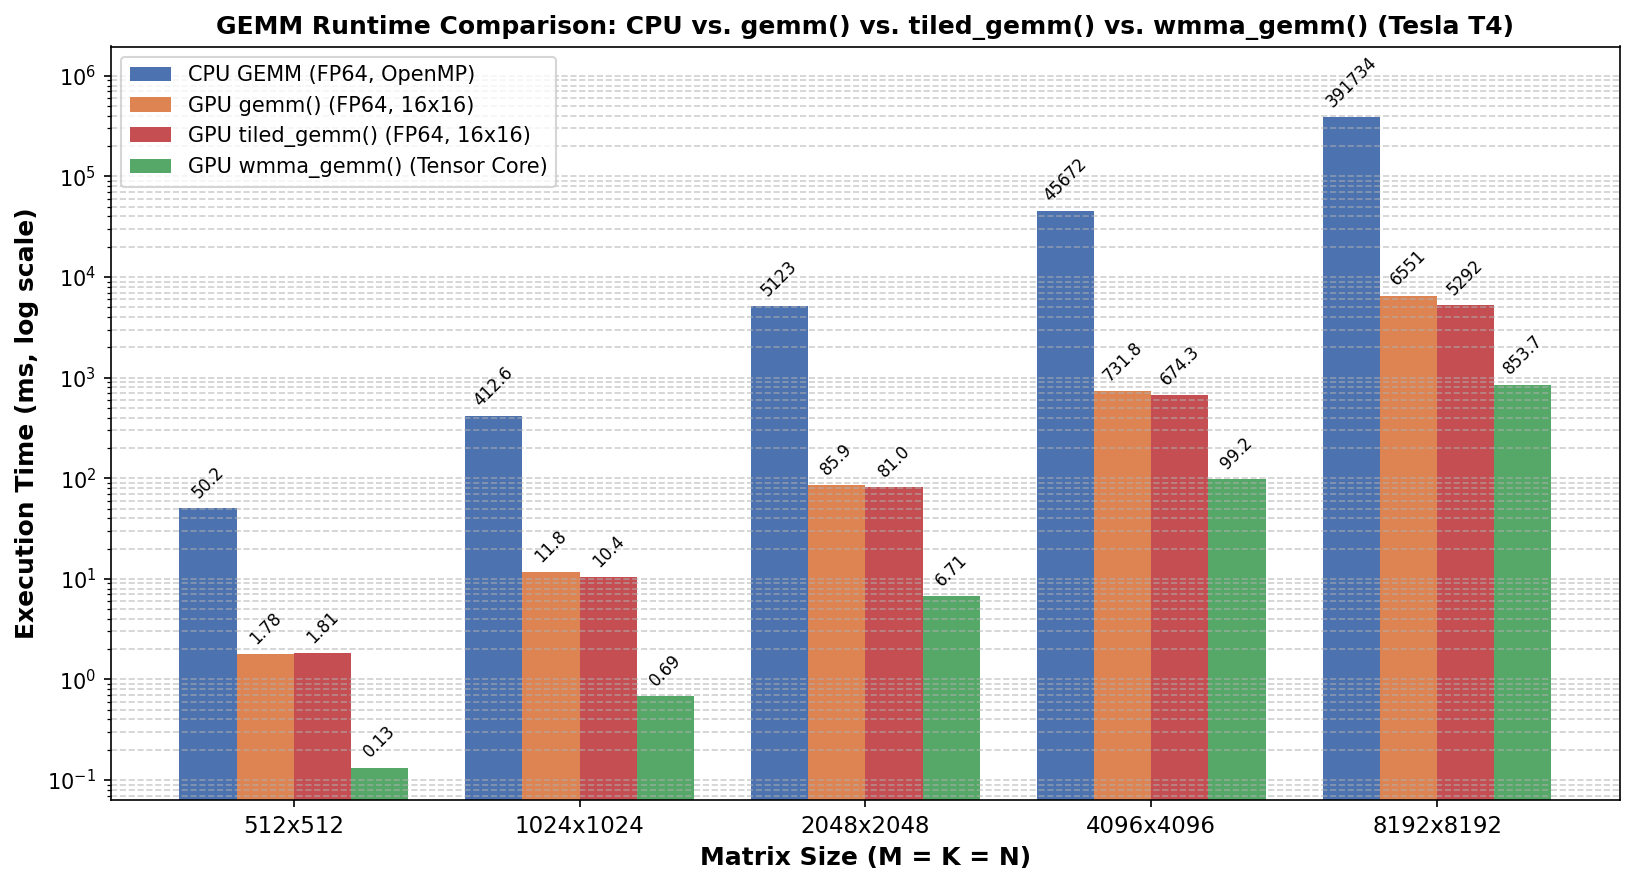

In [1]:
import matplotlib.pyplot as plt
import numpy as np

sizes = ["512x512", "1024x1024", "2048x2048", "4096x4096", "8192x8192"]

# Actual measured runtimes (ms) from Google Colab Tesla T4
cpu_ms        = [50.185878, 412.606772, 5123.276870, 45672.277708, 391734.038359]
gemm_ms       = [1.779302,  11.778032,  85.894150,   731.825012,   6550.681641]
tiled_gemm_ms = [1.811251,  10.407424,  81.017242,   674.290710,   5291.535645]
wmma_ms       = [0.133123,  0.686579,   6.711910,    99.167488,    853.676086]

x = np.arange(len(sizes))
width = 0.20

fig, ax = plt.subplots(figsize=(11, 6), dpi=150)

r1 = ax.bar(x - 1.5 * width, cpu_ms,        width, label="CPU GEMM (FP64, OpenMP)",        color="#4C72B0")
r2 = ax.bar(x - 0.5 * width, gemm_ms,       width, label="GPU gemm() (FP64, 16x16)",       color="#DD8452")
r3 = ax.bar(x + 0.5 * width, tiled_gemm_ms, width, label="GPU tiled_gemm() (FP64, 16x16)", color="#C44E52")
r4 = ax.bar(x + 1.5 * width, wmma_ms,       width, label="GPU wmma_gemm() (Tensor Core)",  color="#55A868")

ax.set_yscale("log")
ax.set_xlabel("Matrix Size (M = K = N)", fontsize=12, fontweight="bold")
ax.set_ylabel("Execution Time (ms, log scale)", fontsize=12, fontweight="bold")
ax.set_title("GEMM Runtime Comparison: CPU vs. gemm() vs. tiled_gemm() vs. wmma_gemm() (Tesla T4)", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(sizes, fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.6, which="both")
ax.legend(fontsize=10, loc="upper left")

def annotate_bars(rects):
    for rect in rects:
        h = rect.get_height()
        txt = f"{h:.2f}" if h < 10 else (f"{h:.1f}" if h < 1000 else f"{h:.0f}")
        ax.annotate(
            txt,
            xy=(rect.get_x() + rect.get_width() / 2, h),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center", va="bottom",
            fontsize=8, rotation=45
        )

for rects in (r1, r2, r3, r4):
    annotate_bars(rects)

plt.ylim(top=max(cpu_ms) * 5)
plt.tight_layout()
plt.savefig("gemm_runtime_comparison.png", dpi=300)
plt.show()